# BUSI 乳腺超声图像分类

本 notebook 用于：

1. 探索 BUSI 数据集（类别分布、样本图像）
2. 自动发现 `outputs/checkpoints/` 中所有已训练的模型
3. 在测试集上统一评估并对比它们的 Accuracy / Precision / Recall / F1
4. 可视化混淆矩阵、预测样例与训练曲线

它会自动扫描 `outputs/checkpoints/*_best.pt`，因此**训练了哪几个模型，就对比哪几个模型**（各种 ResNet 深度、预训练 ViT 变体、从零实现的 ViT 等），无需手动改代码。


In [1]:
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

# 找到项目根目录：从当前目录向上查找包含 config.py 的目录
PROJECT_ROOT = Path.cwd()
for candidate in [PROJECT_ROOT, *PROJECT_ROOT.parents]:
    if (candidate / "config.py").exists():
        PROJECT_ROOT = candidate
        break
else:
    raise FileNotFoundError(
        "未找到 config.py。请确认在项目目录（或其子目录）下启动 Jupyter，"
        "或手动将 PROJECT_ROOT 指向项目根目录。")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import config
from models import build_resnet, build_vit
from utils.dataset import BUSIDataset, build_loaders, get_file_paths
from utils.metrics import compute_metrics
from utils import visualization as viz

print("Project root:", PROJECT_ROOT)
print("PyTorch:", torch.__version__, "| CUDA available:", torch.cuda.is_available())


Project root: e:\jerome\MyCode\BUSI_classification
PyTorch: 2.14.1+cu126 | CUDA available: True


## 1. 数据集探索

Total images (excluding masks): 780
  benign: 437
  malignant: 210
  normal: 133


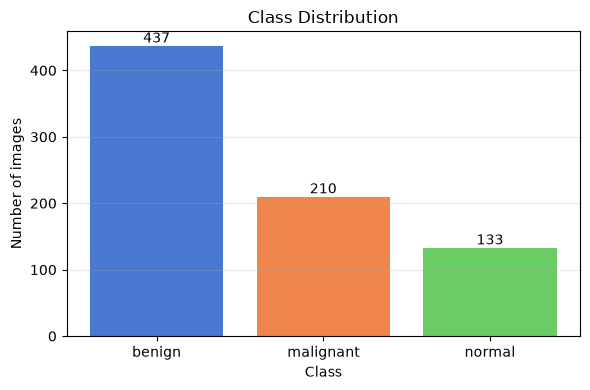

In [2]:
samples = get_file_paths(config.DATA_DIR)
print("Total images (excluding masks):", len(samples))

counts = Counter(label for _, label in samples)
for c in config.CLASSES:
    print(f"  {c}: {counts.get(c, 0)}")

viz.plot_class_distribution(counts, config.CLASSES)
plt.show()


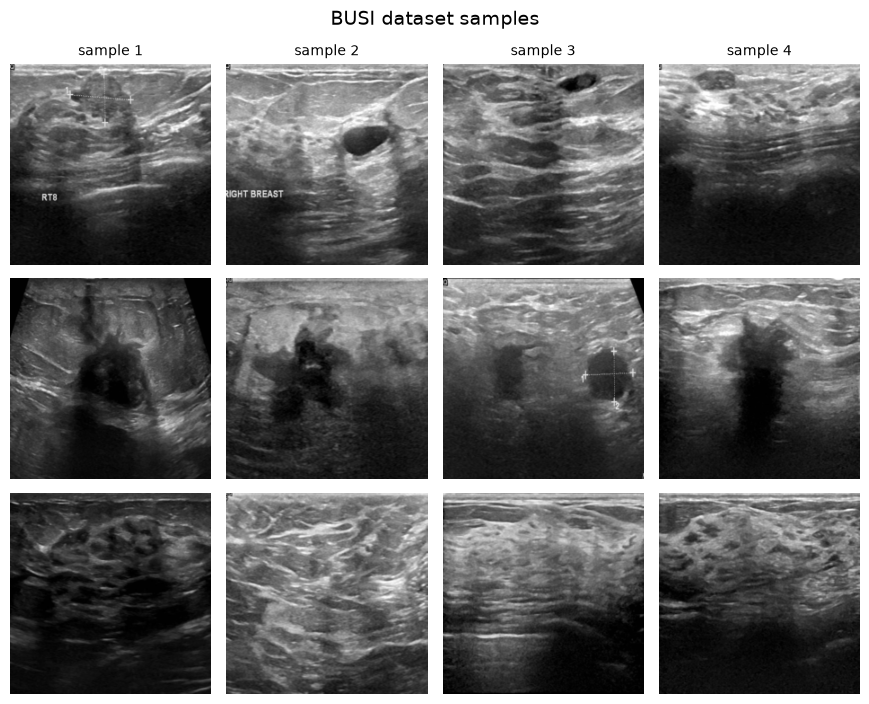

In [3]:
from torchvision import transforms

# 仅用于展示的变换（不做归一化，方便可视化）
display_transform = transforms.Compose([
    transforms.Resize((config.IMG_SIZE, config.IMG_SIZE)),
    transforms.ToTensor(),
])
display_ds = BUSIDataset(samples, config.CLASSES, transform=display_transform)
viz.plot_dataset_samples(display_ds, config.CLASSES, n_per_class=4)
plt.show()


## 2. 数据加载

In [4]:
train_loader, val_loader, test_loader, classes = build_loaders(
    config.DATA_DIR,
    img_size=config.IMG_SIZE,
    batch_size=config.BATCH_SIZE,
    num_workers=0,  # notebook 中避免多进程问题
    ratios=(config.TRAIN_RATIO, config.VAL_RATIO, config.TEST_RATIO),
    seed=config.SEED,
)
print("Classes:", classes)
print("Train:", len(train_loader.dataset),
      "| Val:", len(val_loader.dataset),
      "| Test:", len(test_loader.dataset))


Classes: ['benign', 'malignant', 'normal']
Train: 544 | Val: 118 | Test: 118


## 3. 发现并加载已训练的模型

In [5]:
from torchvision import models as tv_models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# torchvision 预训练 ViT 的架构（评估时不下载权重，直接复用已保存的权重）
TV_VIT_BUILDERS = {
    "b16": tv_models.vit_b_16,
    "b32": tv_models.vit_b_32,
    "l16": tv_models.vit_l_16,
    "l32": tv_models.vit_l_32,
}


def build_model_by_name(name, num_classes):
    """根据 checkpoint 名字构建对应的模型结构（不加载 ImageNet 权重）。"""
    if name.startswith("resnet"):
        depth = int(name[len("resnet"):])
        return build_resnet(depth=depth, num_classes=num_classes, pretrained=False)
    if name == "vit":  # 从零实现的轻量 ViT（使用 config 中的结构参数）
        return build_vit(
            image_size=config.IMG_SIZE, patch_size=config.VIT_PATCH_SIZE,
            num_classes=num_classes, dim=config.VIT_DIM, depth=config.VIT_DEPTH,
            heads=config.VIT_HEADS, mlp_dim=config.VIT_MLP_DIM,
            dropout=config.VIT_DROPOUT)
    # vit_b16 / vit_b32 / vit_l16 / vit_l32 —— torchvision 预训练 ViT
    variant = name.split("_", 1)[1]
    model = TV_VIT_BUILDERS[variant](weights=None, image_size=config.IMG_SIZE)
    in_features = model.heads.head.in_features
    model.heads.head = nn.Linear(in_features, num_classes)
    return model


def model_label(name):
    if name.startswith("resnet"):
        return f"ResNet-{name[len('resnet'):]}"
    if name == "vit":
        return "ViT (custom)"
    variant = name.split("_", 1)[1]
    return f"ViT-{variant[0].upper()}/{variant[1:]} (pretrained)"


# 扫描所有 *_best.pt 权重
checkpoints = sorted(config.CHECKPOINT_DIR.glob("*_best.pt"))
print("Found checkpoints:")
for p in checkpoints:
    print("  ", p.name)

models = {}
for p in checkpoints:
    name = p.stem.replace("_best", "")  # resnet18 / vit / vit_b16 ...
    try:
        model = build_model_by_name(name, len(classes))
        model.load_state_dict(torch.load(p, map_location=device))
        model = model.to(device).eval()
        models[name] = (model, model_label(name))
    except Exception as e:
        print(f"  [skip] {p.name}: {e}")

print(f"\nLoaded {len(models)} models:")
for name, (model, label) in models.items():
    n_params = sum(p.numel() for p in model.parameters())
    print(f"  {label:<26} ({name}): {n_params/1e6:.2f}M params")

if not models:
    print("\nNo trained checkpoints found in", config.CHECKPOINT_DIR)
    print("Please run train.py first, e.g.:")
    print("  python train.py --model resnet --depth 18")
    print("  python train.py --model vit --vit-variant b16")


Found checkpoints:
   resnet18_best.pt
   resnet34_best.pt
   resnet50_best.pt
   vit_b16_best.pt
   vit_best.pt

Loaded 5 models:
  ResNet-18                  (resnet18): 11.18M params
  ResNet-34                  (resnet34): 21.29M params
  ResNet-50                  (resnet50): 23.51M params
  ViT-B/16 (pretrained)      (vit_b16): 85.80M params
  ViT (custom)               (vit): 3.41M params


## 4. 测试集评估与对比

In [6]:
@torch.no_grad()
def predict(model, loader):
    model.eval()
    y_true, y_pred = [], []
    for images, labels in loader:
        images = images.to(device)
        logits = model(images)
        y_true.append(labels.numpy())
        y_pred.append(logits.argmax(dim=1).cpu().numpy())
    return np.concatenate(y_true), np.concatenate(y_pred)

results = {}
for name, (model, label) in models.items():
    y_true, y_pred = predict(model, test_loader)
    results[name] = {"label": label, "y_true": y_true, "y_pred": y_pred,
                     "metrics": compute_metrics(y_true, y_pred)}

rows = []
for name, r in results.items():
    m = r["metrics"]
    rows.append({
        "Model": r["label"],
        "Accuracy": m["accuracy"],
        "Precision(macro)": m["precision"],
        "Recall(macro)": m["recall"],
        "F1(macro)": m["f1"],
    })
summary = pd.DataFrame(rows).sort_values("F1(macro)", ascending=False).reset_index(drop=True)
summary.round(4)


,Model,Accuracy,Precision(macro),Recall(macro),F1(macro)
0,ResNet-50,0.8983,0.8983,0.8831,0.8904
1,ResNet-18,0.8729,0.8510,0.8912,0.8671
2,ResNet-34,0.8220,0.8141,0.8331,0.8227
3,ViT-B/16 (pretrained),0.5339,0.4612,0.4443,0.4394
4,ViT (custom),0.5339,0.4414,0.4022,0.4006


## 5. 混淆矩阵对比

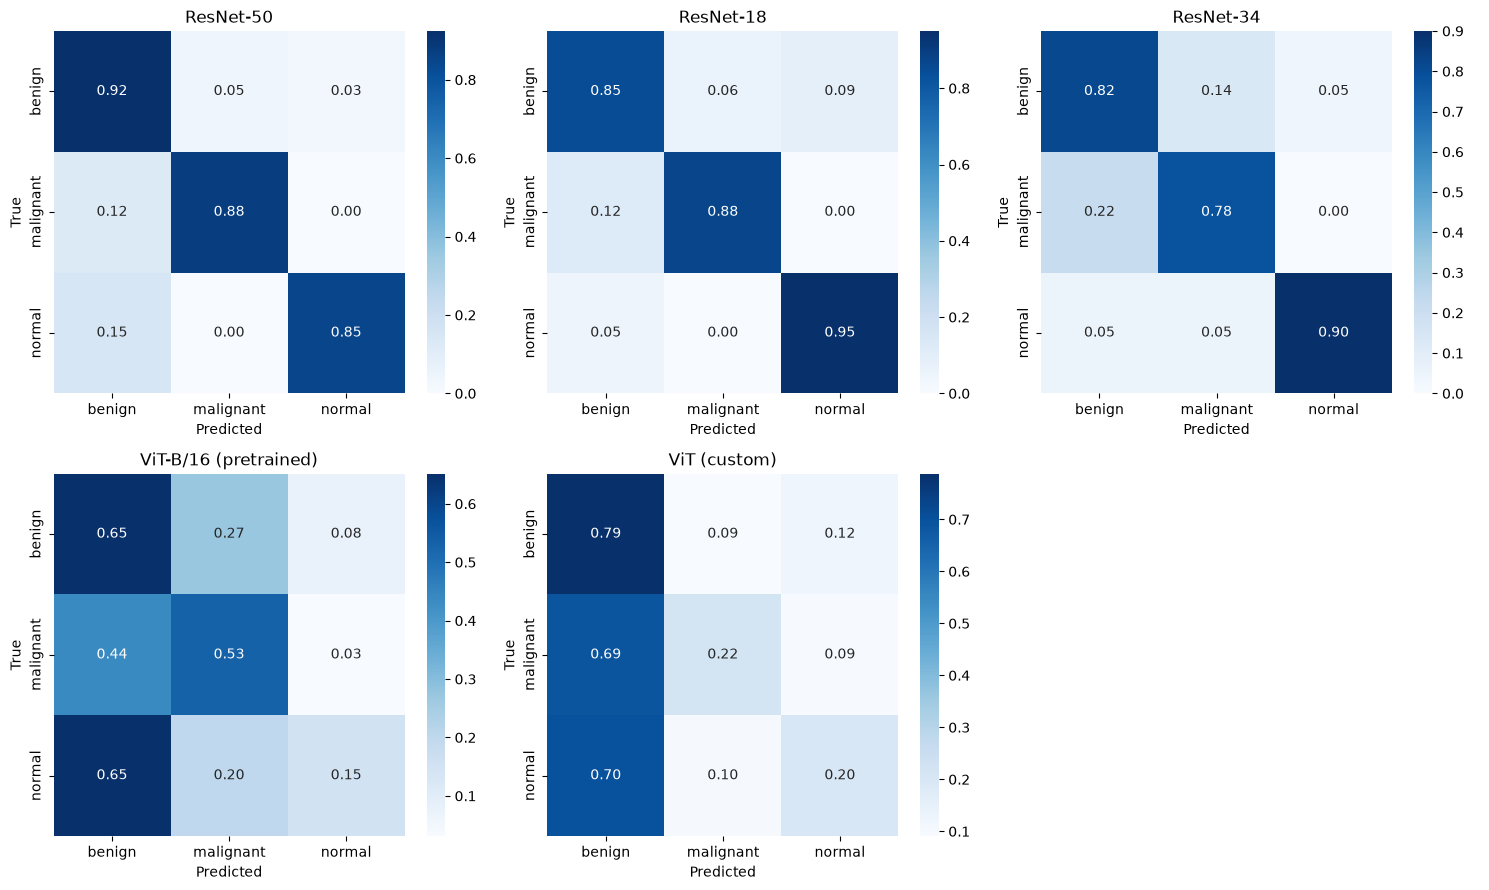

In [7]:
if models:
    n = len(results)
    cols = min(3, n)
    nrows = (n + cols - 1) // cols
    fig, axes = plt.subplots(nrows, cols, figsize=(5 * cols, 4.5 * nrows))
    axes = np.atleast_1d(axes).ravel()

    label_to_name = {r["label"]: name for name, r in results.items()}
    order = summary["Model"].tolist()  # 与上表一致，按 F1 排序

    for ax, label in zip(axes, order):
        name = label_to_name[label]
        viz.plot_confusion_matrix(results[name]["metrics"]["confusion_matrix"],
                                  classes, title=label, ax=ax, normalize=True)
    for ax in axes[len(order):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No models loaded — skip visualization.")


## 6. 预测样例对比

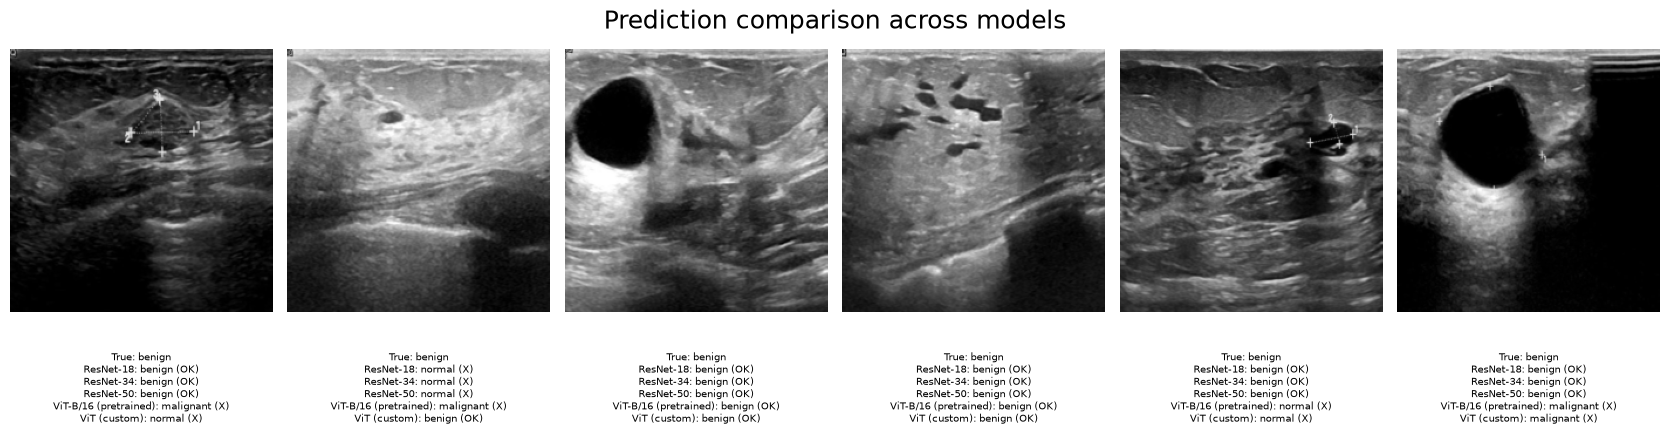

In [14]:
if models:
    images, labels = next(iter(test_loader))
    images, labels = images.to(device), labels.numpy()
    preds = {}
    for name, (model, label) in models.items():
        with torch.no_grad():
            preds[name] = model(images).argmax(dim=1).cpu().numpy()
    n = min(6, len(images))
    fig, axes = plt.subplots(1, n, figsize=(2.8 * n, 4.8))
    for i in range(n):
        img = viz.denormalize(images[i])
        axes[i].imshow(img.permute(1, 2, 0).numpy())
        axes[i].axis("off")

        lines = [f"True: {classes[labels[i]]}"]
        for name, (model, label) in models.items():
            p = preds[name][i]
            mark = "OK" if p == labels[i] else "X"
            lines.append(f"{label}: {classes[p]} ({mark})")

        # 👇 预测文字放到图下方（axes 坐标系，y<0 即在图外下方）
        axes[i].text(
            0.5, -0.15, "\n".join(lines),
            transform=axes[i].transAxes,
            ha="center", va="top", fontsize=7,
        )

    # 👇 suptitle 显式放在顶部，不再跟图抢位置
    plt.suptitle("Prediction comparison across models", y=0.85, fontsize=18)

    # 👇 rect=[left, bottom, right, top]：底部留 12% 给预测文字，顶部留 7% 给 suptitle
    plt.tight_layout(rect=[0, 0.12, 1, 0.93])
    plt.show()
else:
    print("No models loaded — skip visualization.")


## 7. 训练曲线

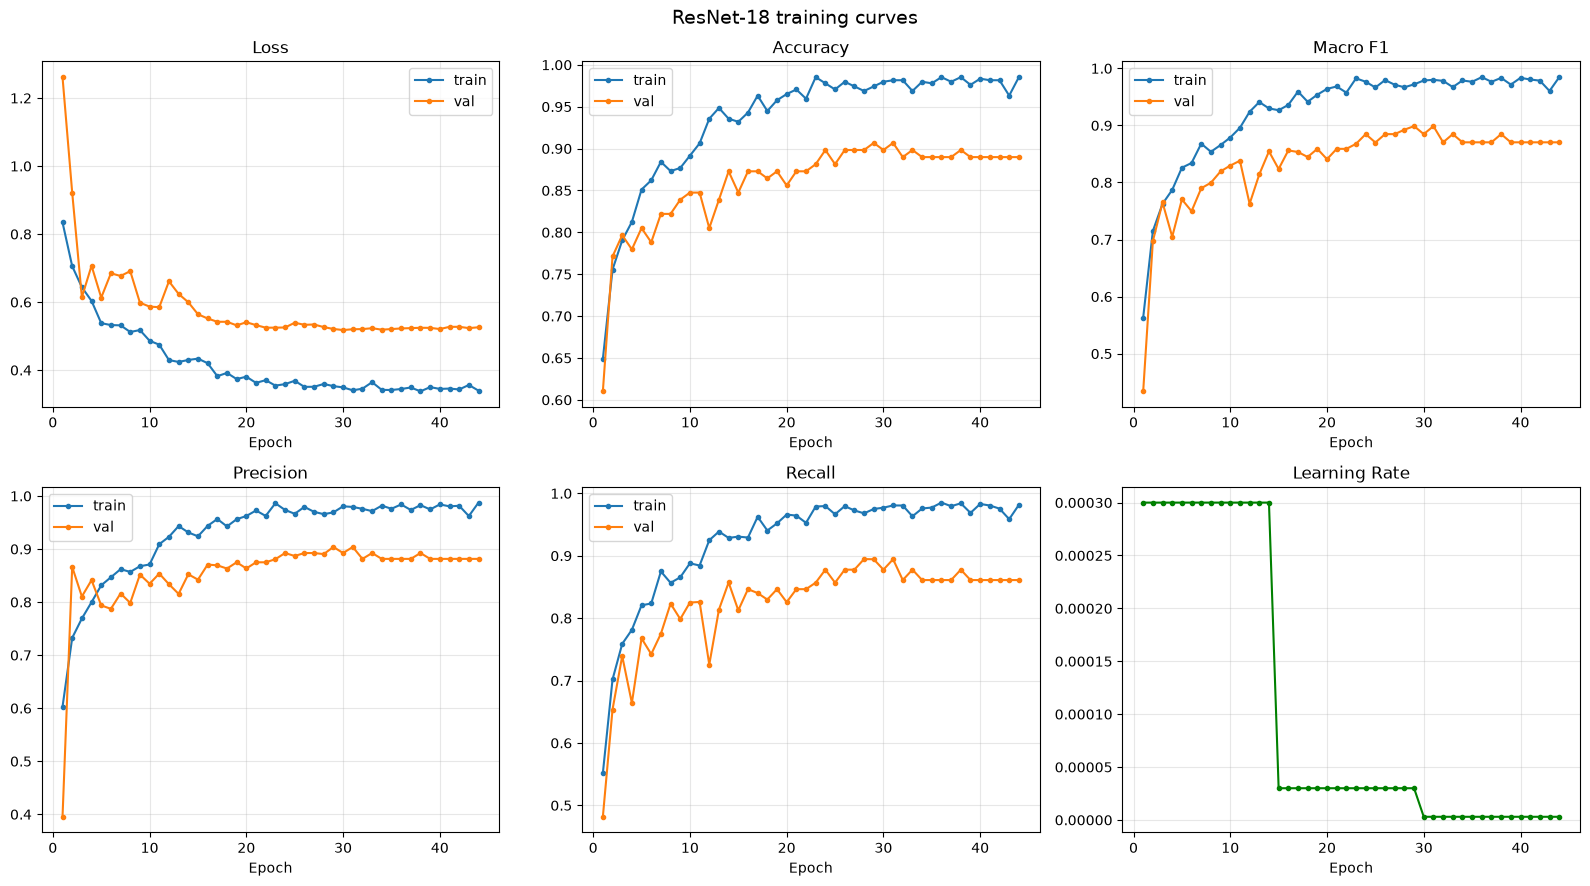

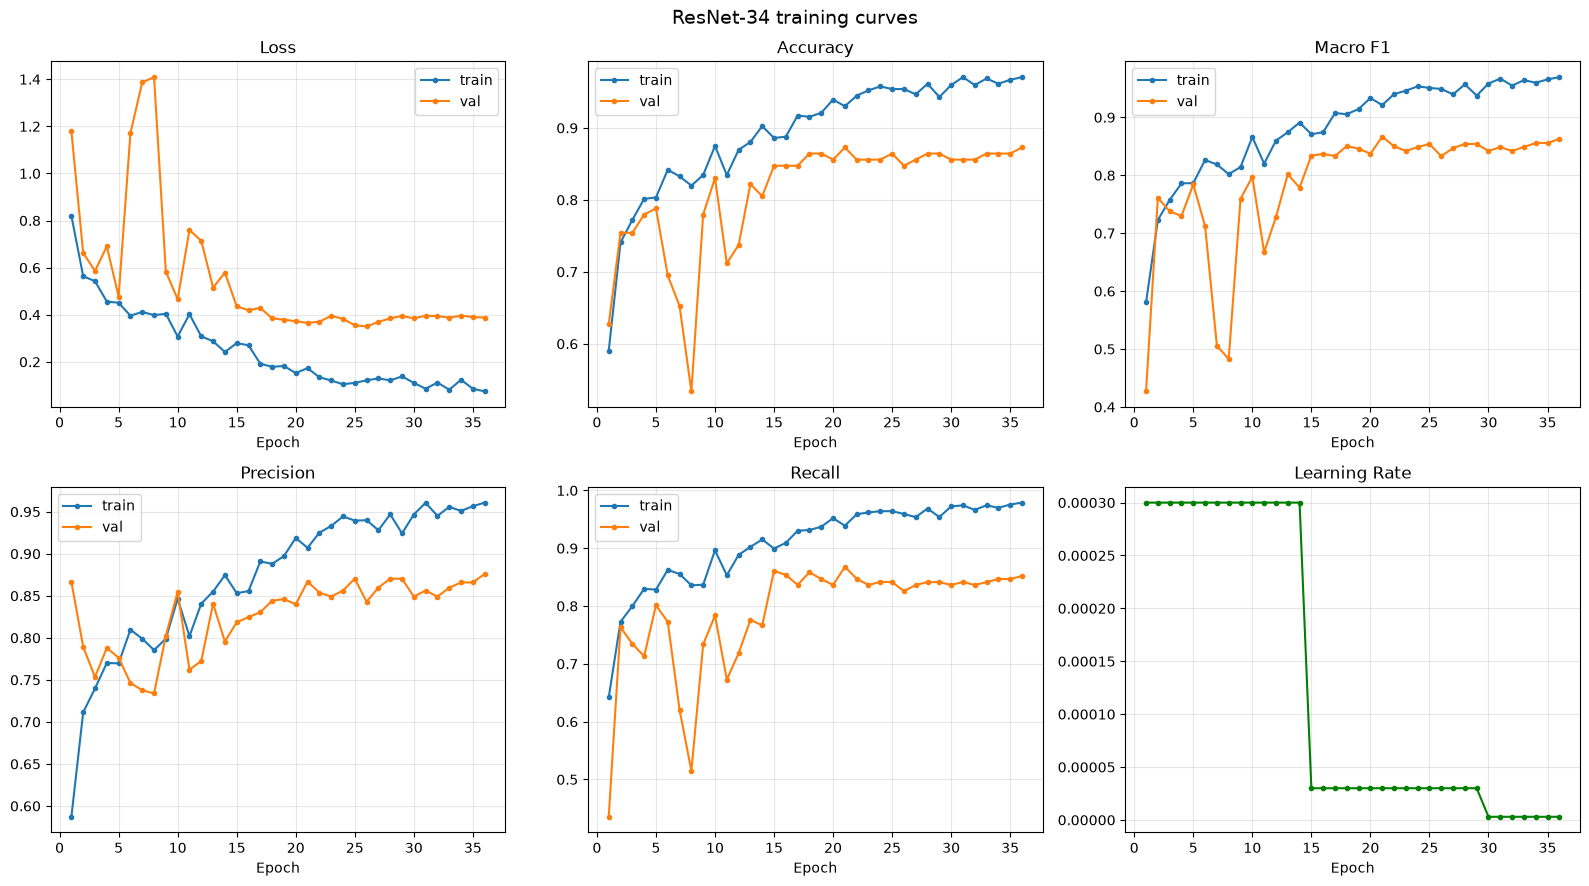

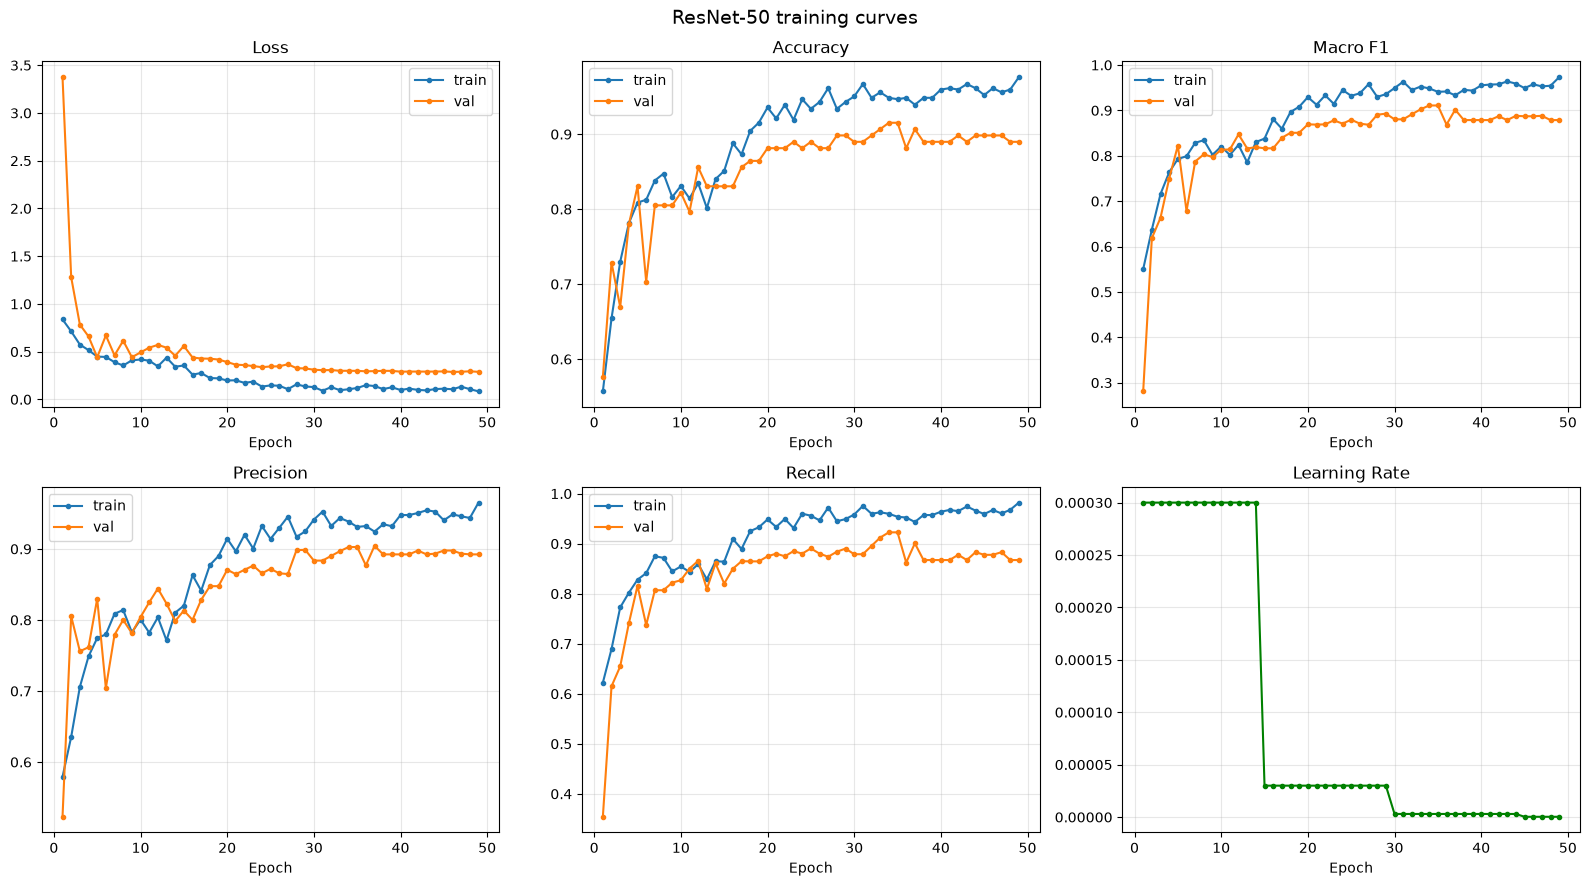

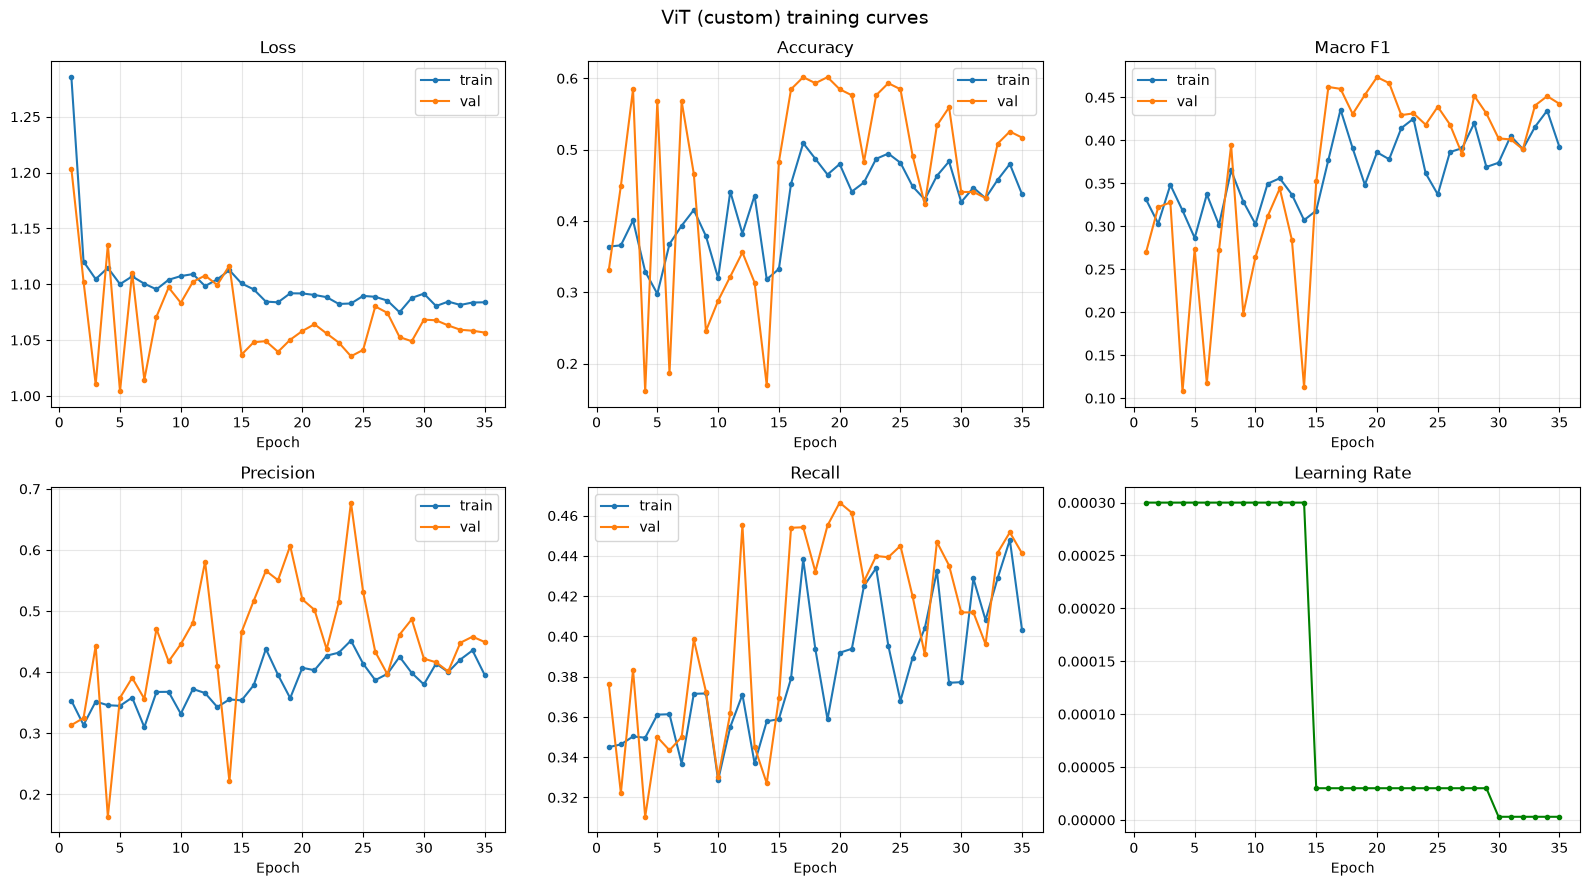

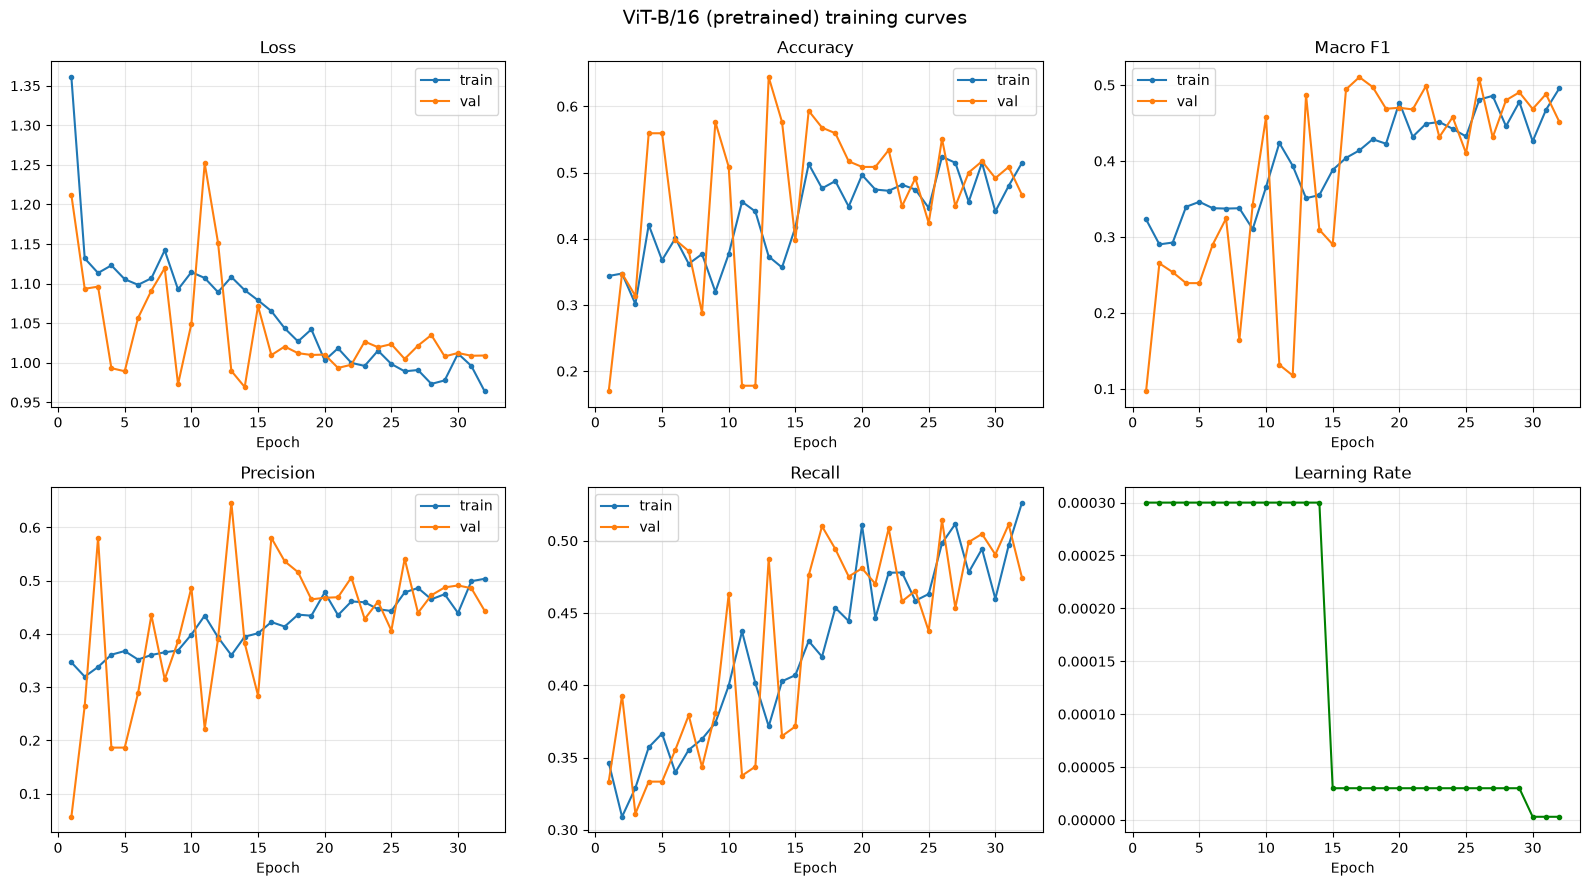

In [9]:
import json

def load_history(path):
    with open(path, encoding="utf-8") as f:
        return json.load(f)

if models:
    for name in sorted(models.keys()):
        hist_path = config.LOG_DIR / f"{name}_history.json"
        if hist_path.exists():
            viz.plot_training_curves(load_history(hist_path),
                                     title=f"{models[name][1]} training curves")
            plt.show()
        else:
            print(f"No history found: {hist_path}")
else:
    print("No models loaded — skip visualization.")


## 8. 结论

- 上方表格汇总了 `outputs/checkpoints/` 中**所有已训练模型**的测试集指标（按 macro F1 排序）。
- 混淆矩阵与预测样例可直观对比不同 ResNet 深度、预训练 ViT 变体（b16/b32/l16/l32）与从零实现的轻量 ViT 之间的差异。
- 小数据集上 ResNet 通常更稳；预训练 ViT 与从零 ViT 之间也可直接对比。
- 训练曲线来自 `outputs/logs/{model}_history.json`，可对比各模型的收敛过程。

> 如果某个从零实现的 ViT 是用非默认结构参数训练出来的，Notebook 会按 `config.py` 的默认结构加载，可能导致权重不匹配；此时请保持默认结构训练，或手动修改 `build_model_by_name`。
